# Corridas MEIGA con la fuente $^{241}$Am-Be: comparación de medios y escalado al montaje blindado

Corridas recuperadas del TOSHIBA y extraídas al ADATA (`ADATA HD330/Simulacion-fuente-241AmBe/`): agua pura, 2.5 % y 10 % NaCl, **1 637 458 neutrones cada una**, inyección `eCircle` (r = 0.2 m, z = 1.5 m) **vertical por la tapa**, QGSP_BERT_HP sin S(α,β). Archivo de entrada: `Espectro-completo-neutrones-fuente-AmBe241.txt` (437 energías, sesgado). Agua pura: solo `output.json` y archivos procesados.

Informe: `informe/Informe-corridas-AmBe.pdf`.

## 1. Extracción (requiere el ADATA conectado; ya hecha)
`scripts/extraer_carga.py` (carga y E0 por evento desde `output.json`) y `scripts/procesar_pasos.sh` (resumen por evento, capturas, residuos, gammas de captura; solo NaCl). Las celdas se omiten si los resultados existen.

In [1]:
import os, subprocess, sys, runpy, json
if not os.path.exists('resultados/carga_nacl10.npz'):
    runpy.run_path('scripts/extraer_carga.py', run_name='__main__')
if not os.path.exists('resultados/eventos_nacl10.tsv.gz'):
    subprocess.run(['bash', 'scripts/procesar_pasos.sh'], check=True)
sorted(os.listdir('resultados'))

['capturas_nacl10.tsv.gz',
 'capturas_nacl25.tsv.gz',
 'carga_nacl10.npz',
 'carga_nacl25.npz',
 'carga_pura.npz',
 'cargas_robustas.npz',
 'comparacion_exp_sim.json',
 'escalado_373272.tsv',
 'eventos_nacl10.tsv.gz',
 'eventos_nacl25.tsv.gz',
 'experimento_cargas.npz',
 'experimento_tomas.json',
 'gammas_captura_nacl10.tsv.gz',
 'gammas_captura_nacl25.tsv.gz',
 'histograma_carga_simulado.tsv',
 'inelasticos_nacl10.tsv.gz',
 'inelasticos_nacl25.tsv.gz',
 'log_procesar_pasos.txt',
 'neutrones_por_medio.json',
 'neutrones_por_medio.tsv',
 'residuos_nacl10.tsv.gz',
 'residuos_nacl25.tsv.gz',
 'resumen_corridas.json',
 'sin_fondo_nacl10.tsv',
 'sin_fondo_nacl25.tsv',
 'sin_fondo_pura.tsv',
 'sin_fondo_resumen.json']

## 2. Análisis, reponderación al ISO 8529 y escalado
Cada evento se pondera con $w_j = P_{ISO}(\text{celda}_j)/(n_j/N)$, lo que lleva la energía media de 4.064 a 4.211 MeV (ISO 4.211). Halo y fondo usan la respuesta de la Campaña 1 (misma inyección por la tapa) promediada con su espectro.

In [2]:
runpy.run_path('scripts/analizar_corridas.py', run_name='__main__');

nacl25 capturas 1002377 primario 977575 secundarios 24802 sin residuo 0


nacl10 capturas 1082920 primario 1042227 secundarios 40693 sin residuo 0


{
 "pura": {
  "eps_Q1": {
   "archivo": 0.3613155268715289,
   "u_archivo": 0.0003754061706410113,
   "ISO": 0.36436572511638954,
   "u_ISO": 0.00041700061853321347
  },
  "Q_media_senal": {
   "archivo": 3.484085734713229,
   "ISO": 3.5391005985977007,
   "u_ISO": 0.005680371701058477
  }
 },
 "nacl25": {
  "eps_Q1": {
   "archivo": 0.4187698249359678,
   "u_archivo": 0.0003855464263827519,
   "ISO": 0.4215626870410249,
   "u_ISO": 0.00042788150909260706
  },
  "Q_media_senal": {
   "archivo": 7.76986020492389,
   "ISO": 7.79486949558889,
   "u_ISO": 0.01394226150819489
  }
 },
 "nacl10": {
  "eps_Q1": {
   "archivo": 0.49117534617681796,
   "u_archivo": 0.0003906764818948686,
   "ISO": 0.4937980898295964,
   "u_ISO": 0.0004332124003479758
  },
  "Q_media_senal": {
   "archivo": 11.164755016604934,
   "ISO": 11.15975594214061,
   "u_ISO": 0.01556908687534701
  }
 }
}
medio	componente	N	eps_Q1	eventos_senal	eta_cap	capturas	Q_media_senal_pe	carga_total_pe	eventos_Q20
Agua pura	haz	130

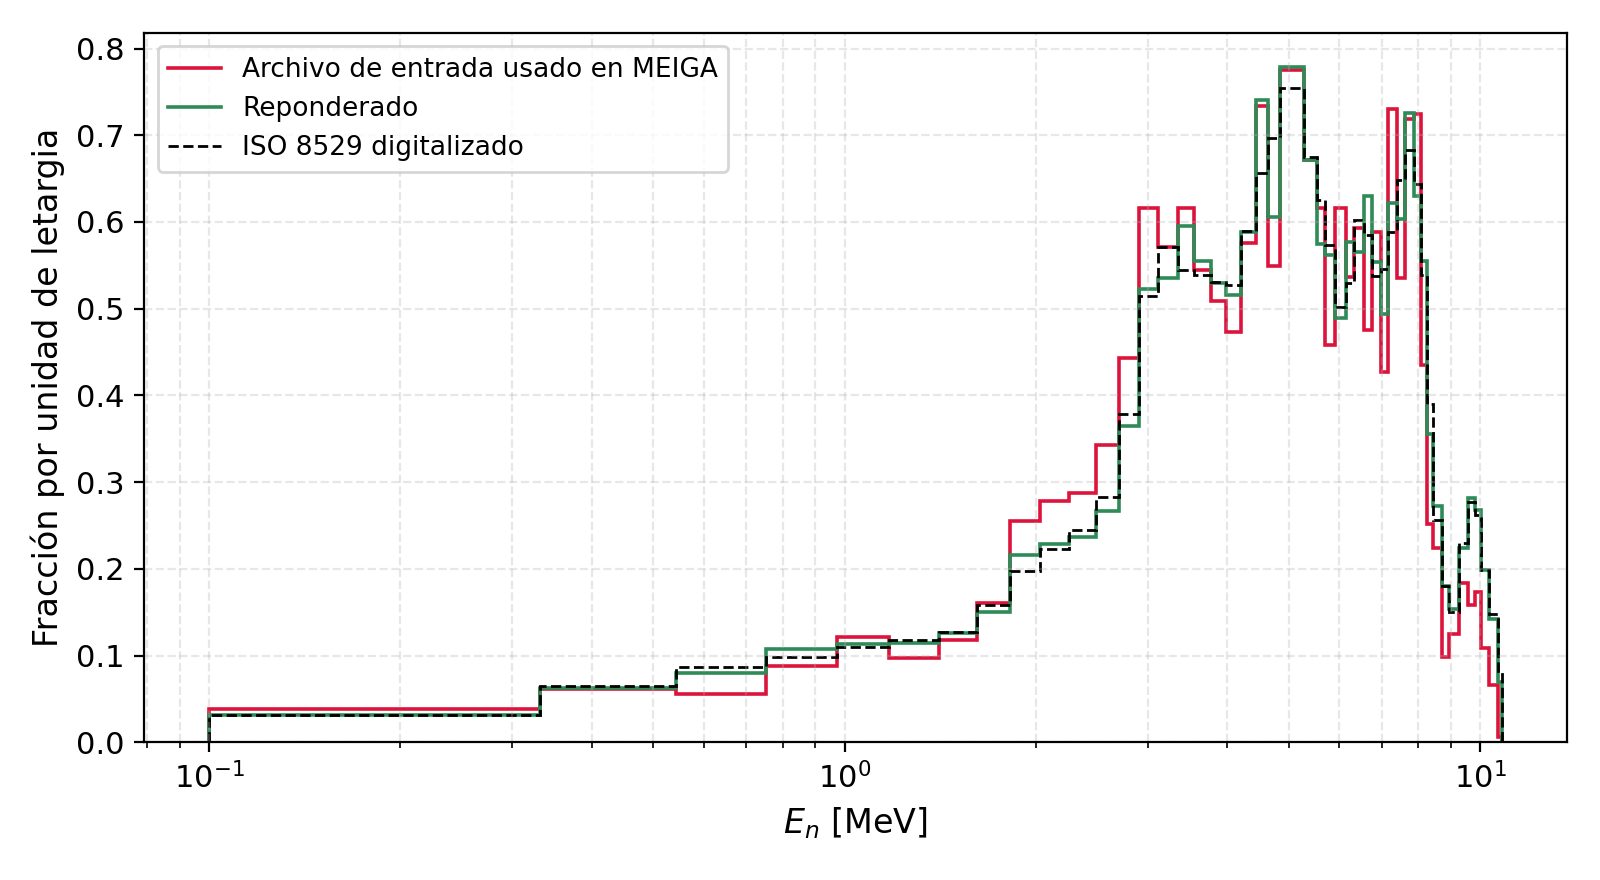

In [3]:
from IPython.display import Image
Image('figuras/fig06_reponderacion.png', width=820)

### Comparación de medios
La reponderación cambia la eficiencia unos 0.3 puntos y la carga menos del 2 %. El NaCl aumenta la eficiencia $Q\geq1$ por neutrón (36.4 → 42.2 → 49.4 %) y, sobre todo, las señales grandes ($Q\geq20$: ×13 y ×27). En 2.5/10 % el ³⁵Cl concentra el 35.5/67.4 % de las capturas, como en las corridas de 500 MeV. ⟨Q|Q≥1⟩ (3.54/7.79/11.16 p.e.) es coherente con la Campaña 1.

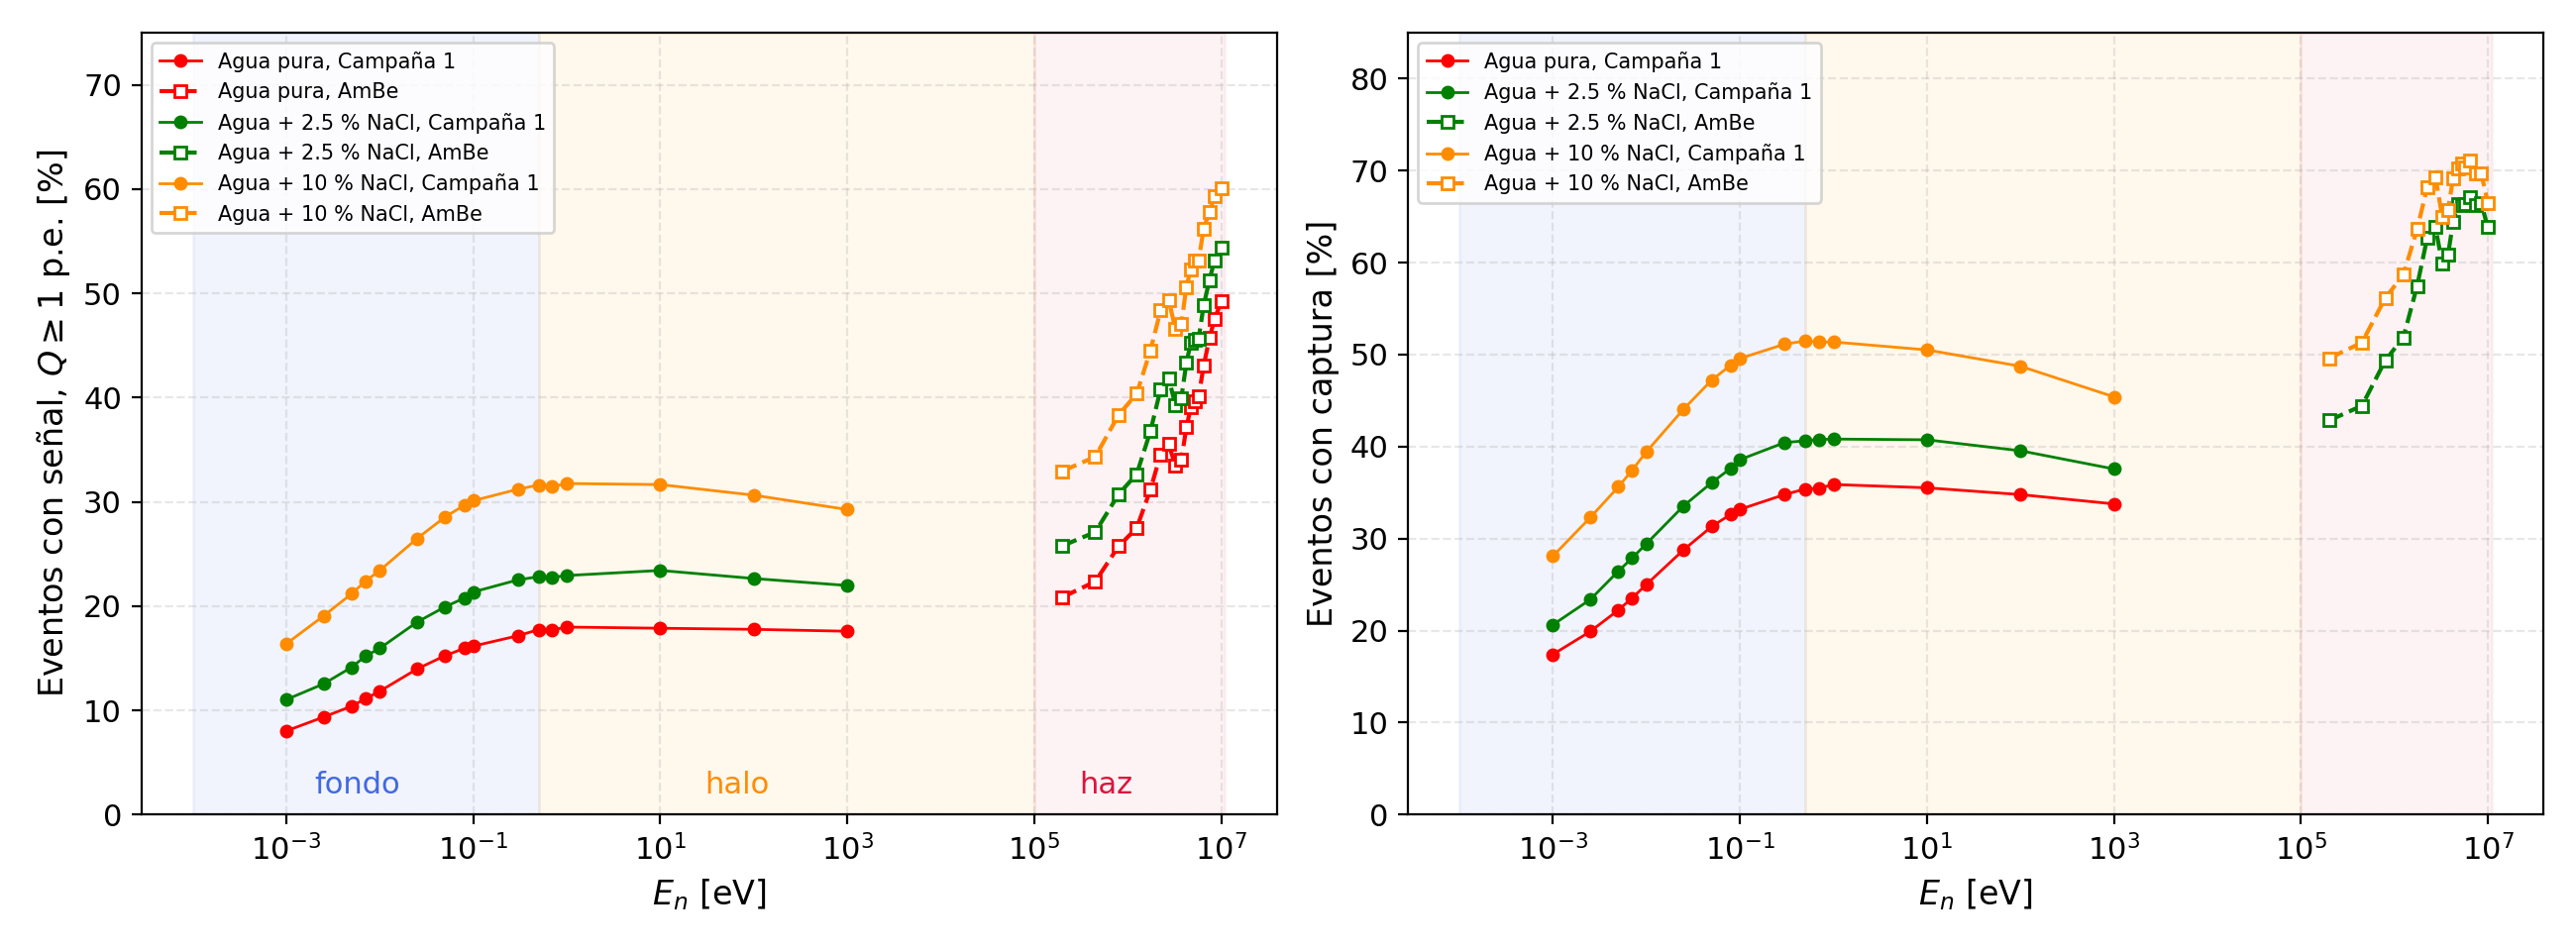

In [4]:
from IPython.display import Image
Image('figuras/fig01_respuesta_vs_energia.png', width=820)

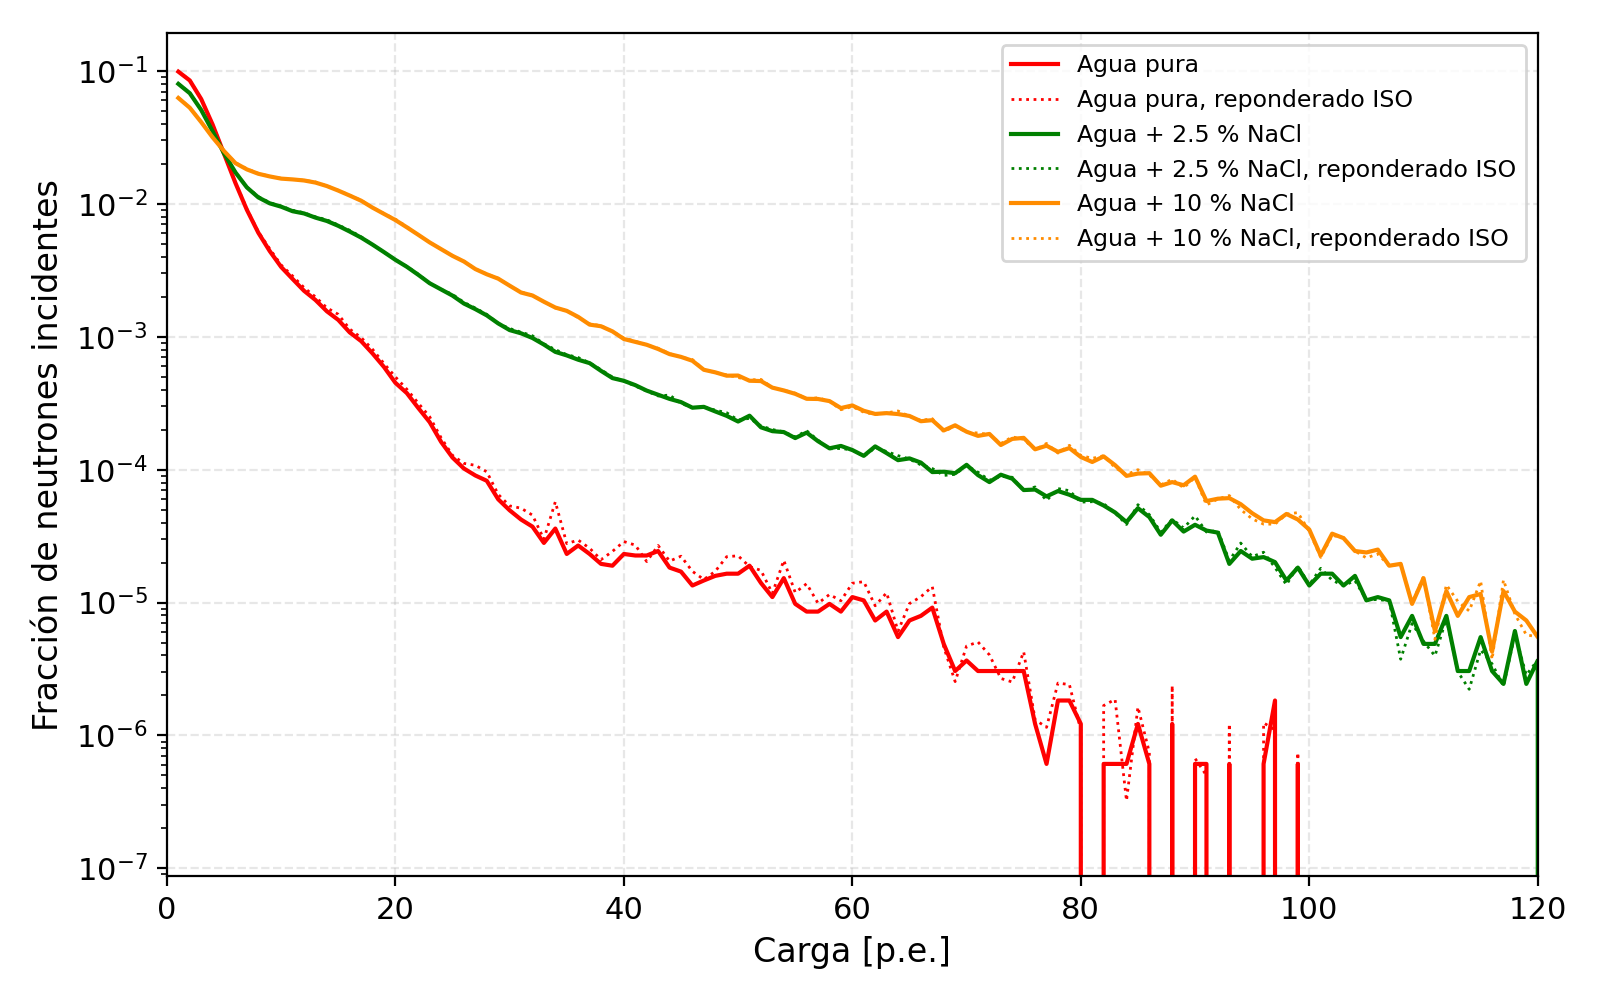

In [5]:
from IPython.display import Image
Image('figuras/fig02_histograma_carga.png', width=820)

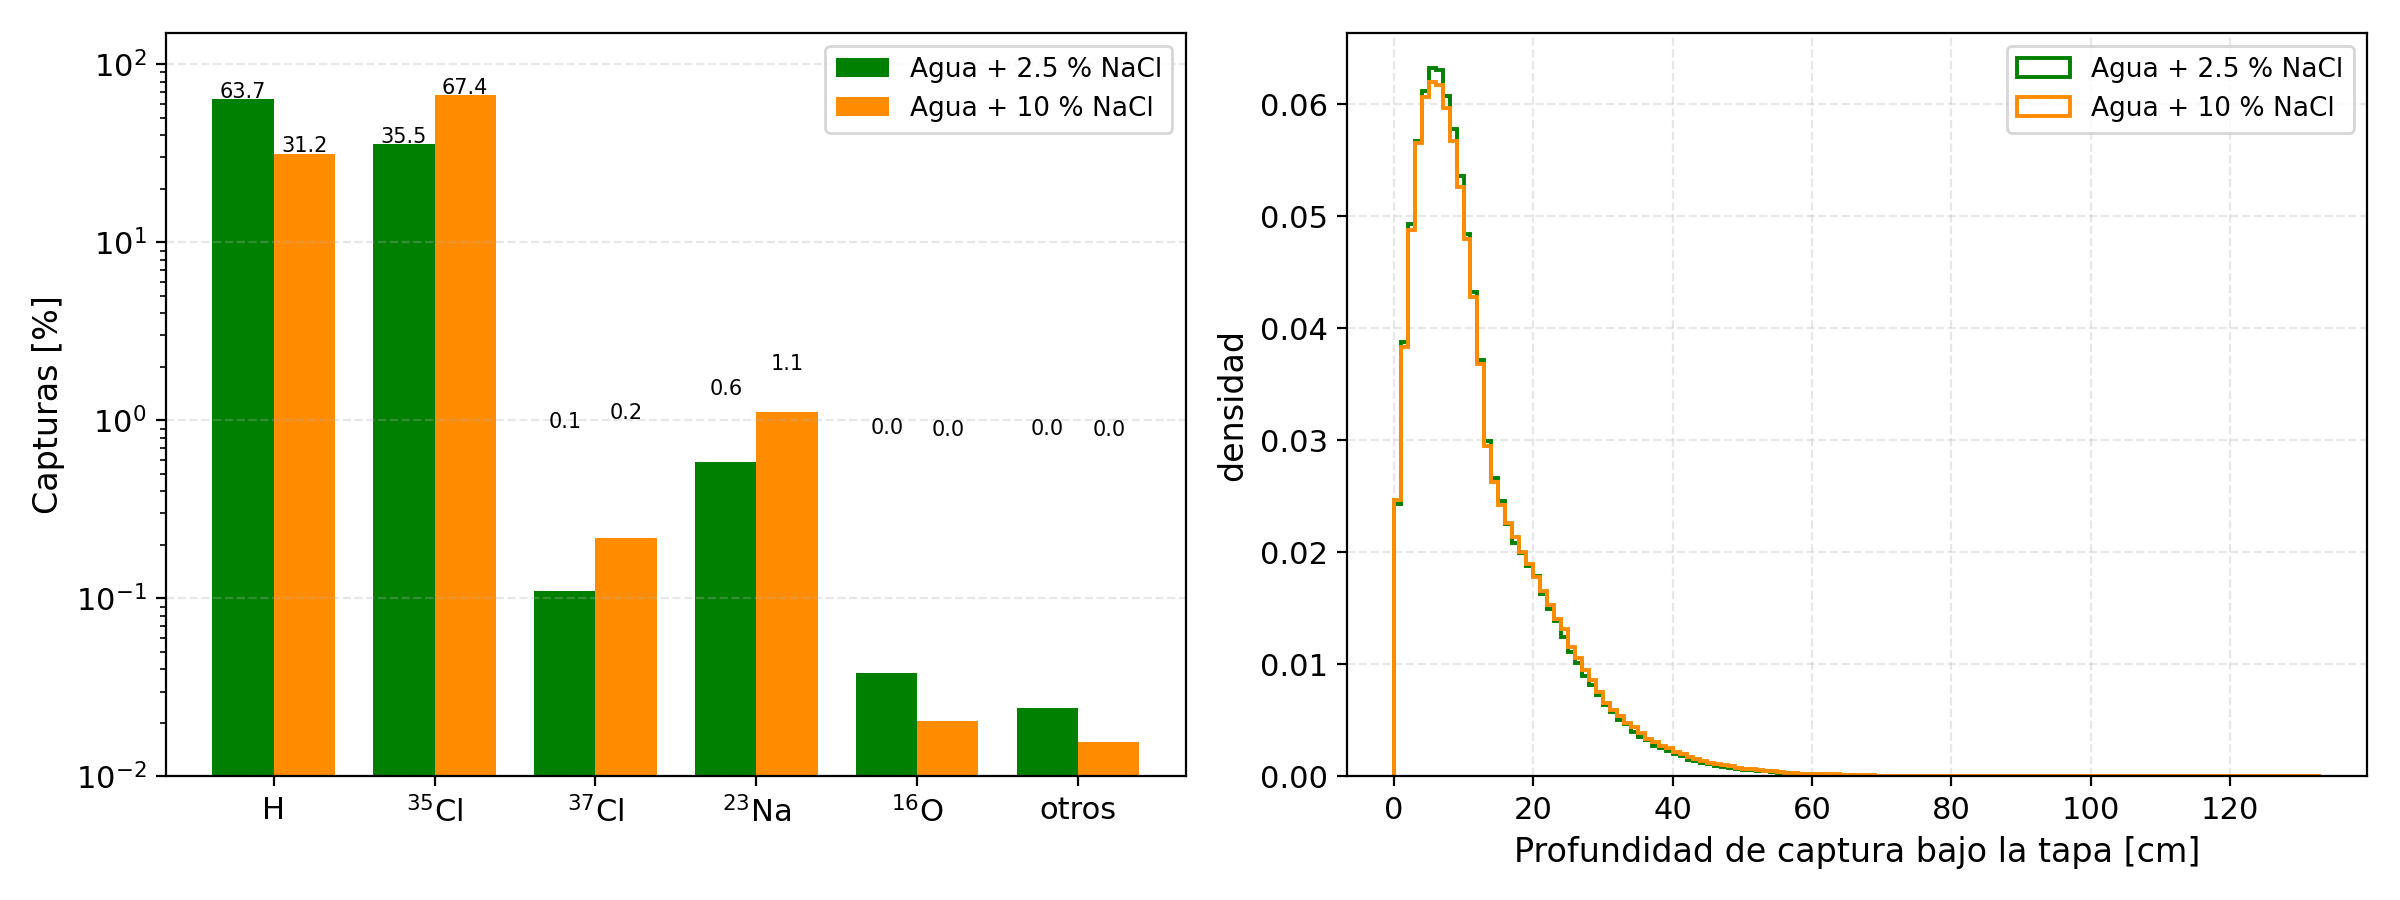

In [6]:
from IPython.display import Image
Image('figuras/fig03_nucleo_profundidad.png', width=820)

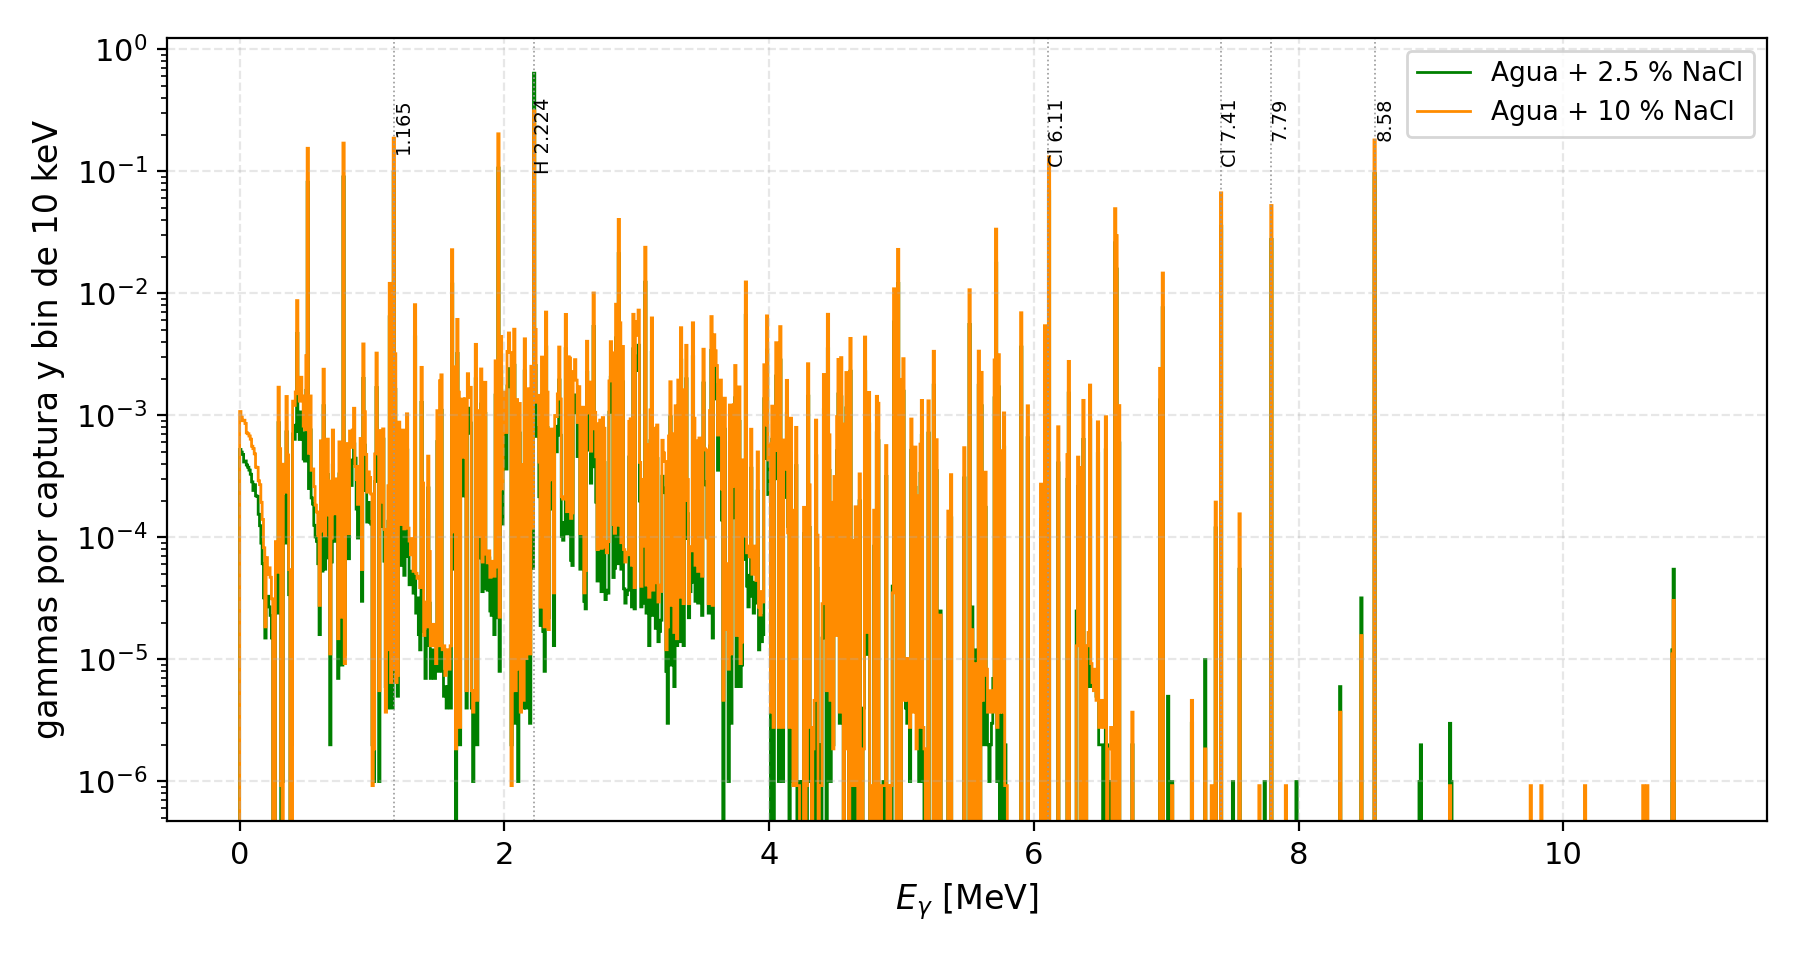

In [7]:
from IPython.display import Image
Image('figuras/fig04_gammas_captura.png', width=820)

In [8]:
d = json.load(open('resultados/resumen_corridas.json'))
{m: {k: d['corridas'][m][k] for k in ('eps_Q1', 'Q_media_senal', 'eta_cap')} for m in d['corridas']}

{'pura': {'eps_Q1': {'archivo': 0.3613155268715289,
   'u_archivo': 0.0003754061706410113,
   'ISO': 0.36436572511638954,
   'u_ISO': 0.00041700061853321347},
  'Q_media_senal': {'archivo': 3.484085734713229,
   'ISO': 3.5391005985977007,
   'u_ISO': 0.005680371701058477},
  'eta_cap': {'ISO': 0.5685062702878017,
   'u_ISO': 0.025603655812380388,
   'estimado': True,
   'metodo_A': 0.594109926100182,
   'metodo_B': 0.5429026144754212,
   'P_senal_captura_supuesta': 0.5877908752093188,
   'P_senal_sin_captura_supuesta': 0.037333585268113714}},
 'nacl25': {'eps_Q1': {'archivo': 0.4187698249359678,
   'u_archivo': 0.0003855464263827519,
   'ISO': 0.4215626870410249,
   'u_ISO': 0.00042788150909260706},
  'Q_media_senal': {'archivo': 7.76986020492389,
   'ISO': 7.79486949558889,
   'u_ISO': 0.01394226150819489},
  'eta_cap': {'archivo': 0.6121518842009993,
   'ISO': 0.6125255416039506,
   'u_ISO': 0.00042213166259849453}},
 'nacl10': {'eps_Q1': {'archivo': 0.49117534617681796,
   'u_archiv

### Captura del haz en agua pura (estimada)
Sin archivos de pasos, $\eta_{cap}$ se estima con dos métodos (eficiencia medida + probabilidades condicionales de 2.5 %; cociente agua pura/2.5 % de la Campaña 1): 59.4 % y 54.3 %, se adopta (56.9 ± 2.6) %.

## 3. Escalado a los 373 272 neutrones del montaje blindado (5 min, 1 Ci)

In [9]:
import pandas as pd
pd.read_csv('resultados/escalado_373272.tsv', sep='\t')

,medio,componente,N,eps_Q1,eventos_senal,eta_cap,capturas,Q_media_senal_pe,carga_total_pe,eventos_Q20
0,Agua pura,haz,130711,0.364366,47626.608296,0.568506,74310.023096,3.539101,1.685554e+05,395.497837
1,Agua pura,halo,167963,0.177210,29764.697398,0.345932,58103.741141,3.174936,9.450102e+04,63.280850
2,Agua pura,fondo,74598,0.146054,10895.362430,0.301126,22463.403276,3.195421,3.481528e+04,24.439387
3,Agua pura,total,373272,0.236521,88286.668124,0.414918,154877.167513,3.373914,2.978717e+05,483.218073
4,Agua + 2.5 % NaCl,haz,130711,0.421563,55102.880386,0.612526,80063.826069,7.794869,4.295198e+05,5172.673966
5,Agua + 2.5 % NaCl,halo,167963,0.225083,37805.541846,0.390295,65555.082188,7.468191,2.823390e+05,3270.848333
6,Agua + 2.5 % NaCl,fondo,74598,0.192359,14349.574247,0.349501,26072.076794,7.459342,1.070384e+05,1232.859695
7,Agua + 2.5 % NaCl,total,373272,0.287345,107257.996479,0.459962,171690.985050,7.634836,8.188972e+05,9676.381993
8,Agua + 10 % NaCl,haz,130711,0.493798,64544.842120,0.661602,86478.654752,11.159756,7.203047e+05,10547.793028
9,Agua + 10 % NaCl,halo,167963,0.303370,50954.860316,0.479048,80462.262851,10.581417,5.391746e+05,7557.644641


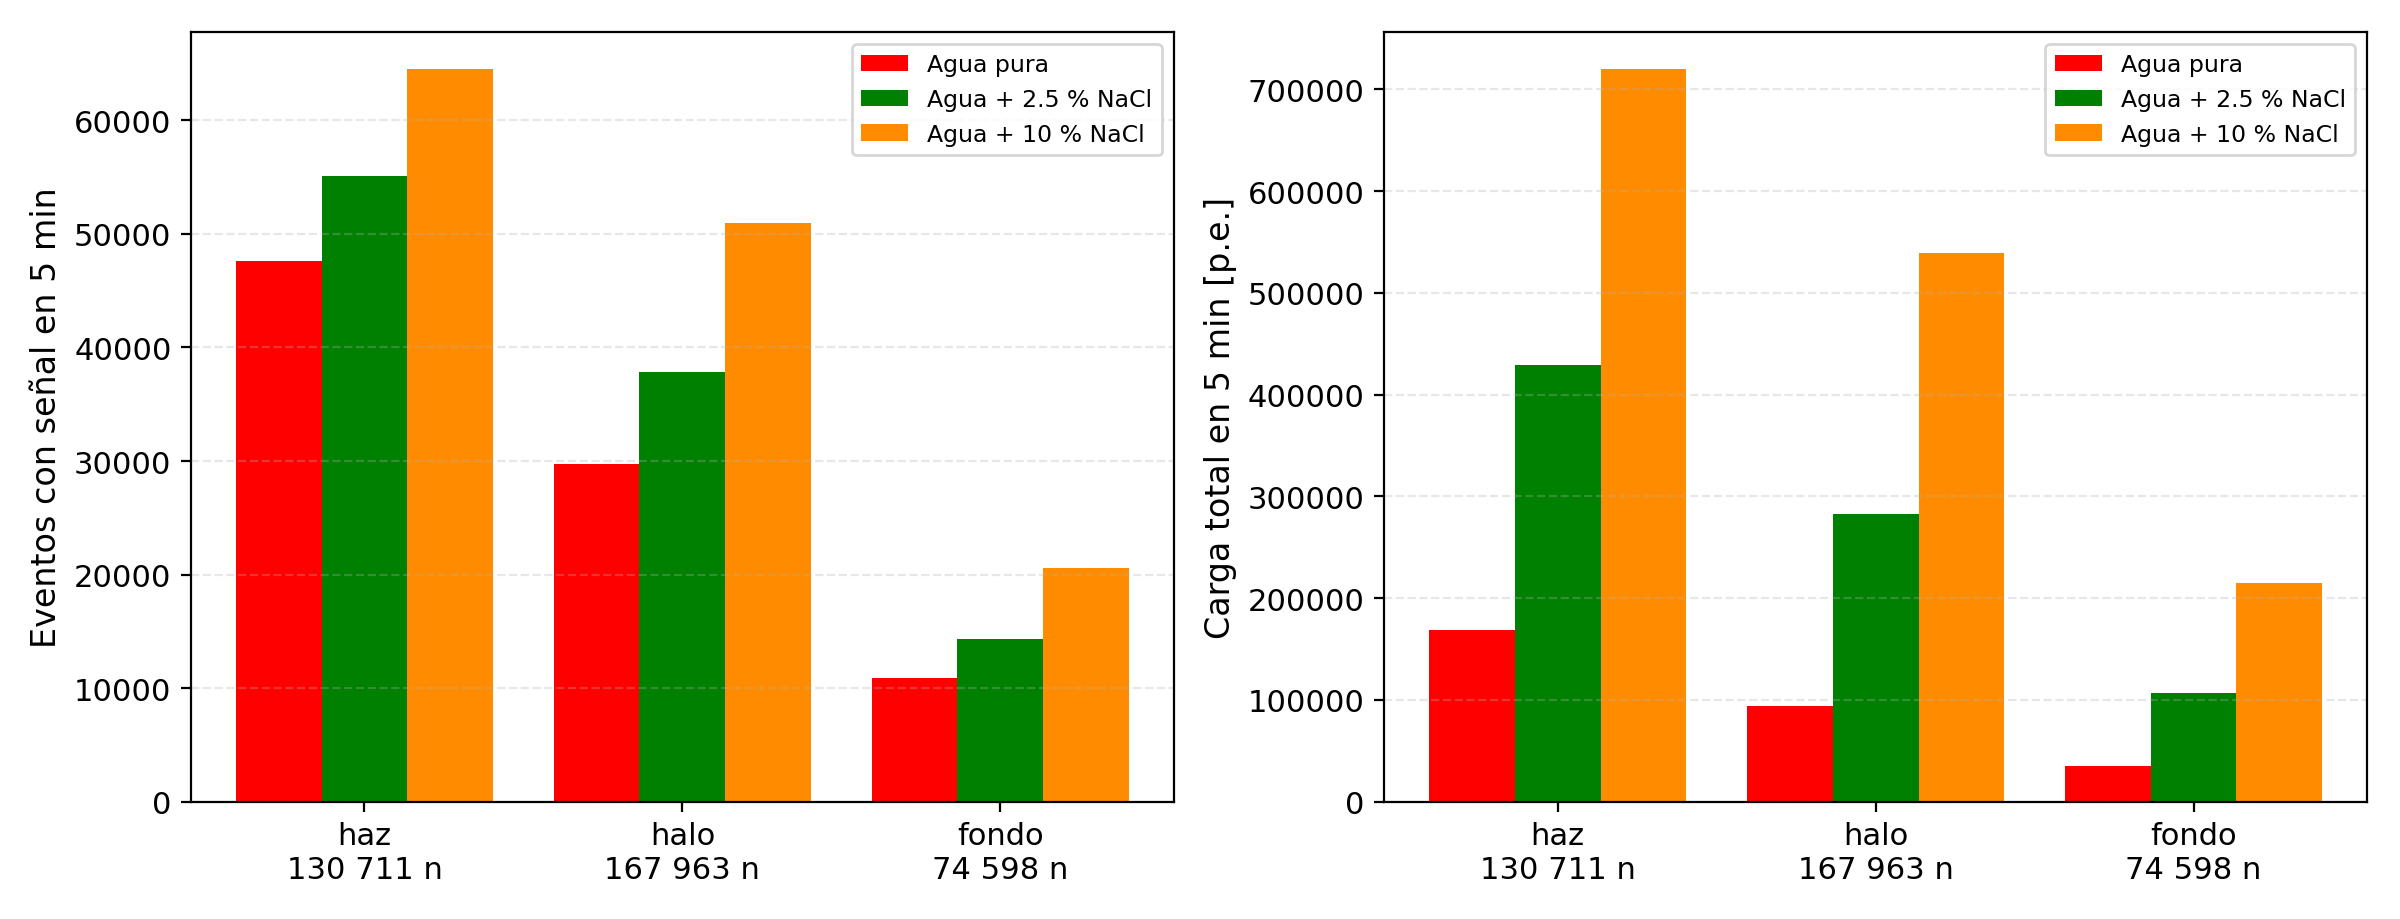

In [10]:
from IPython.display import Image
Image('figuras/fig05_escalado_componentes.png', width=820)

**Resultado:** 88 287 / 107 258 / 136 065 eventos con señal en 5 min (agua pura / 2.5 % / 10 %), es decir 294 / 358 / 454 s⁻¹. Frente a agua pura, el NaCl multiplica las señales por 1.21 y 1.54, la carga total por 2.75 y 4.95 y los eventos con Q ≥ 20 p.e. por 20 y 44.

> **Salvedad:** todas las corridas usadas inyectan por la tapa, mientras que el montaje real irradia por el costado (el PMT está en la tapa). Los absolutos son una estimación; los cocientes NaCl/agua pura son más robustos. Para la cifra definitiva hay que correr en MEIGA el archivo de 373 272 neutrones.

## 4. Histograma de carga y comparación con el detector prototipo
`datos/histogramas_comparados.txt` del notebook `analisis-datos-Flujo-Completo-Bga.ipynb` (TOSHIBA, `Detector-prototipo/Nuevo-analisis/`) es exactamente el histograma de carga de las corridas Am-Be. Aquí se construye además el histograma esperado del montaje en 5 min y se compara con las tomas LAGO del prototipo, con el mismo algoritmo de carga del notebook (ventana positiva alrededor de la muestra 8, pico > 1200 ADC) y la calibración 3.95 p.e./1000 ADC. Las tomas duran 300 s, salvo `10_neutrones`, que dura **240 s**: la resta fuente − fondo se normaliza por tiempo.

In [11]:
if not os.path.exists('resultados/experimento_cargas.npz'):
    runpy.run_path('scripts/procesar_experimento.py', run_name='__main__')
json.load(open('resultados/experimento_tomas.json'))

{'pura_fondo': {'disparos': 125401,
  'lineas_datos': 4012832,
  'segmentos_32': 125401,
  'alineado': True,
  'segundos_gps': 300,
  'duracion_s': 300,
  'errores_lectura': 299,
  'pulsos_carga': 79682,
  'tasa_disparo_s': 418.00333333333333,
  'tasa_pulsos_s': 265.6066666666667},
 'pura_neutrones': {'disparos': 563961,
  'lineas_datos': 18046752,
  'segmentos_32': 563961,
  'alineado': True,
  'segundos_gps': 300,
  'duracion_s': 300,
  'errores_lectura': 299,
  'pulsos_carga': 194459,
  'tasa_disparo_s': 1879.87,
  'tasa_pulsos_s': 648.1966666666667},
 '2.5_fondo': {'disparos': 114226,
  'lineas_datos': 3655256,
  'segmentos_32': 114226,
  'alineado': False,
  'segundos_gps': 299,
  'duracion_s': 299,
  'errores_lectura': 299,
  'pulsos_carga': 88827,
  'tasa_disparo_s': 382.0267558528428,
  'tasa_pulsos_s': 297.0802675585284},
 '2.5_neutrones': {'disparos': 1099688,
  'lineas_datos': 35190016,
  'segmentos_32': 1099688,
  'alineado': True,
  'segundos_gps': 300,
  'duracion_s': 300

In [12]:
runpy.run_path('scripts/comparar_exp_sim.py', run_name='__main__');

{
 "pura": {
  "sim_5min_Q>=1": 88286.66812381767,
  "sim_5min_Q>=5": 18269.089056925197,
  "sim_5min_Q>=10": 4038.465594330252,
  "sim_corrida_Q>=1": 591639.0,
  "exp_5min_neto_Q>=5": 114777.0,
  "exp_5min_neto_Q>=10": 114770.0,
  "exp_5min_neto_Q>=20": 52345.0,
  "t_fuente_s": 300,
  "t_fondo_s": 300,
  "exp_pulsos_fuente": 194459,
  "exp_pulsos_fondo": 79682,
  "exp_tasa_neta_s": 382.59000000000003,
  "exp_carga_mediana_neta_pe": 23.087750000000003,
  "error_resta_notebook_pct": 0.0,
  "cociente_exp/sim_Q>=5": 6.28257925955492,
  "cociente_exp/sim_Q>=10": 28.419209553531857
 },
 "nacl25": {
  "sim_5min_Q>=1": 107257.99647863802,
  "sim_5min_Q>=5": 47052.65353965126,
  "sim_5min_Q>=10": 27294.450248679645,
  "sim_corrida_Q>=1": 685718.0,
  "exp_5min_neto_Q>=5": 574584.9197324415,
  "exp_5min_neto_Q>=10": 574575.9397993311,
  "exp_5min_neto_Q>=20": 282848.18394648825,
  "t_fuente_s": 300,
  "t_fondo_s": 299,
  "exp_pulsos_fuente": 663709,
  "exp_pulsos_fondo": 88827,
  "exp_tasa_neta_

{'pura': {'muones_pico_ADC': 41000.0, 'muones_pico_pe': 161.95, 'N_efectivo_Q>=10': 10608095.188, 'N_efectivo_Q>=10_pct_emitidos': 1.593, 'N_efectivo_Q>=20': 40435000.113, 'N_efectivo_Q>=20_pct_emitidos': 6.071, 'factor_forma_Q20_120': 106.757}, 'nacl25': {'muones_pico_ADC': 39000.0, 'muones_pico_pe': 154.05, 'N_efectivo_Q>=10': 7857755.267, 'N_efectivo_Q>=10_pct_emitidos': 1.18, 'N_efectivo_Q>=20': 10911031.353, 'N_efectivo_Q>=20_pct_emitidos': 1.638, 'factor_forma_Q20_120': 29.116}, 'nacl10': {'muones_pico_ADC': 39000.0, 'muones_pico_pe': 154.05, 'N_efectivo_Q>=10': 14735758.341, 'N_efectivo_Q>=10_pct_emitidos': 2.213, 'N_efectivo_Q>=20': 20743142.013, 'N_efectivo_Q>=20_pct_emitidos': 3.115, 'factor_forma_Q20_120': 55.25}}


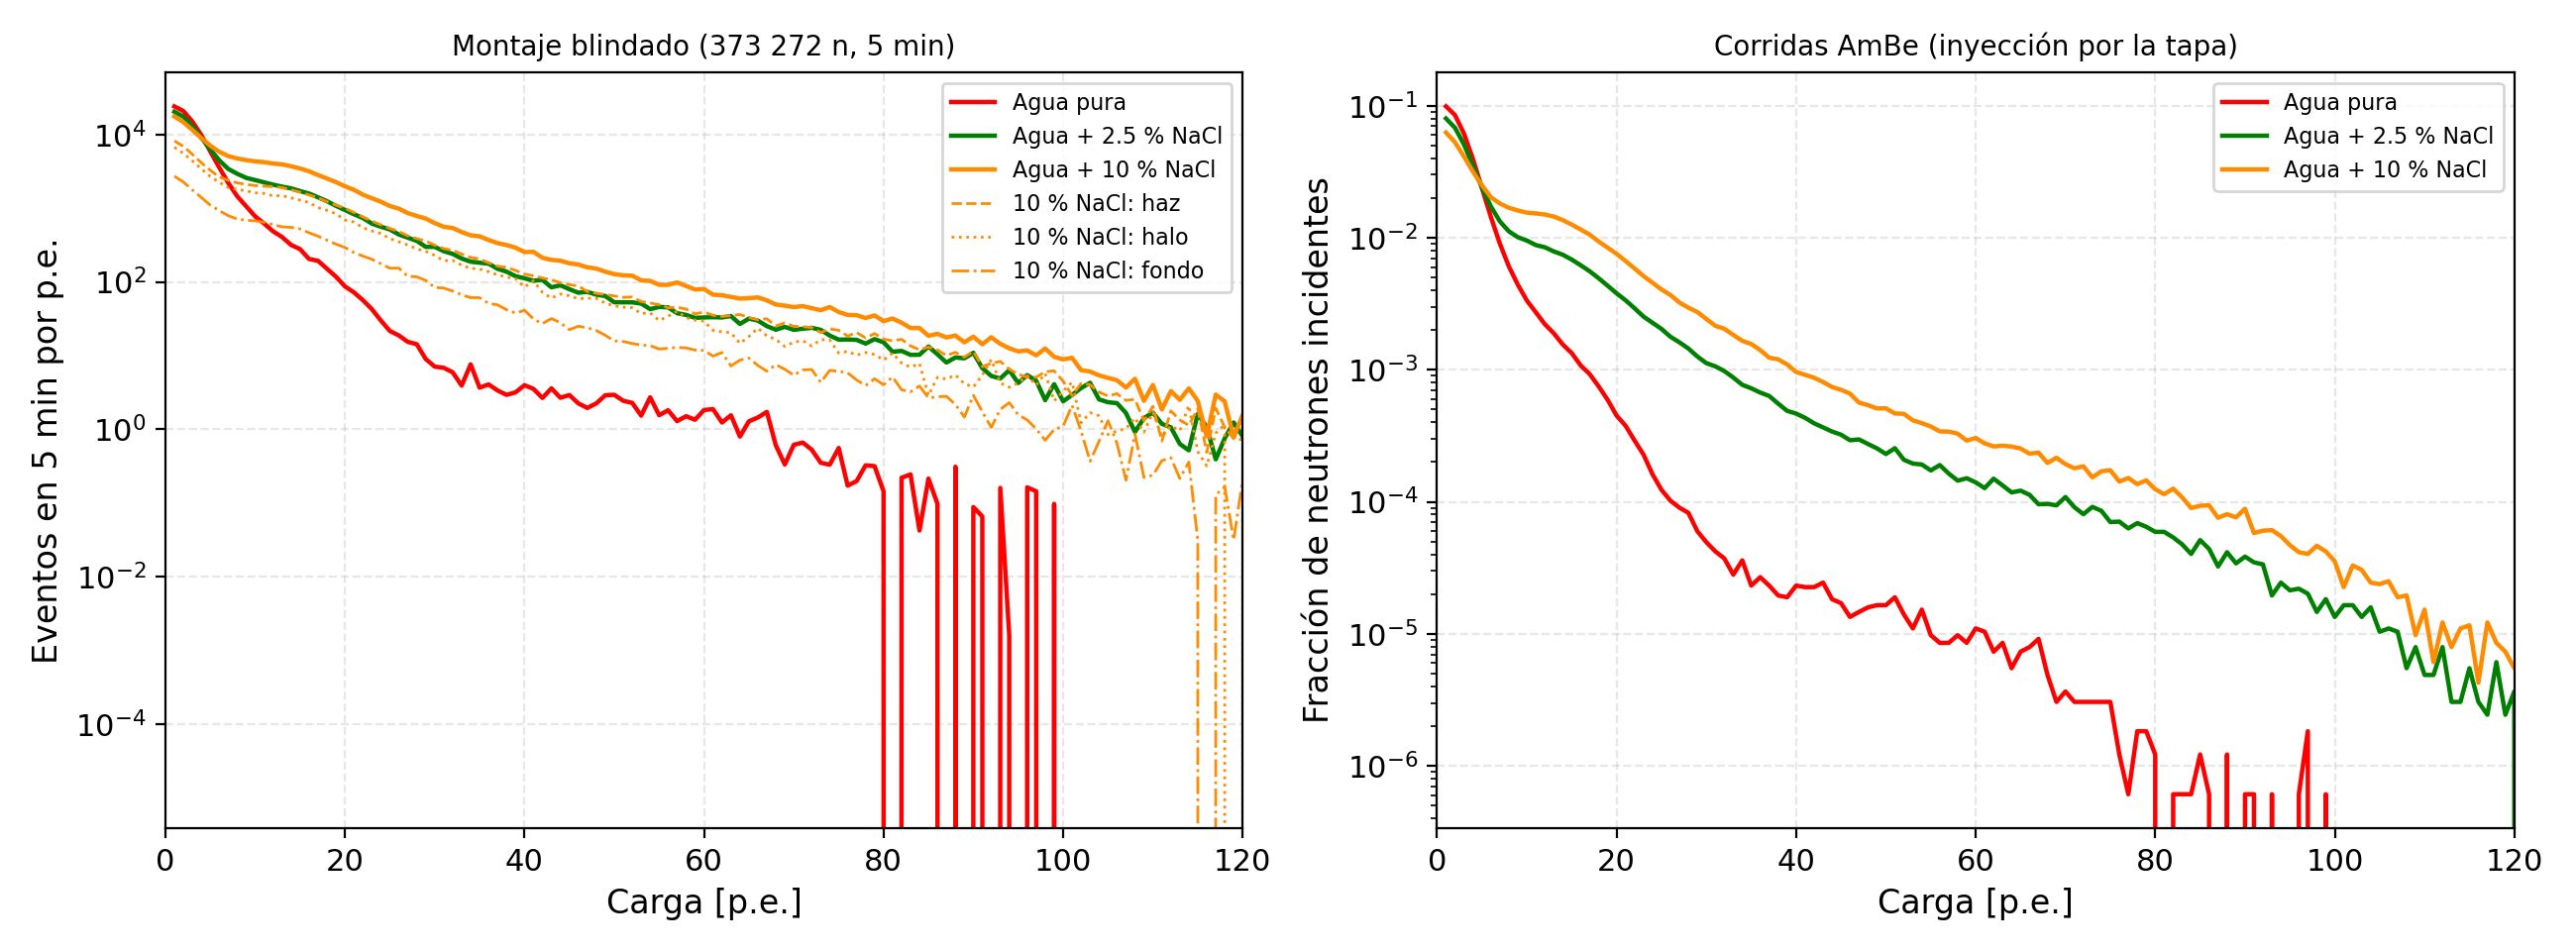

In [13]:
from IPython.display import Image
Image('figuras/fig07_histograma_carga_simulado.png', width=820)

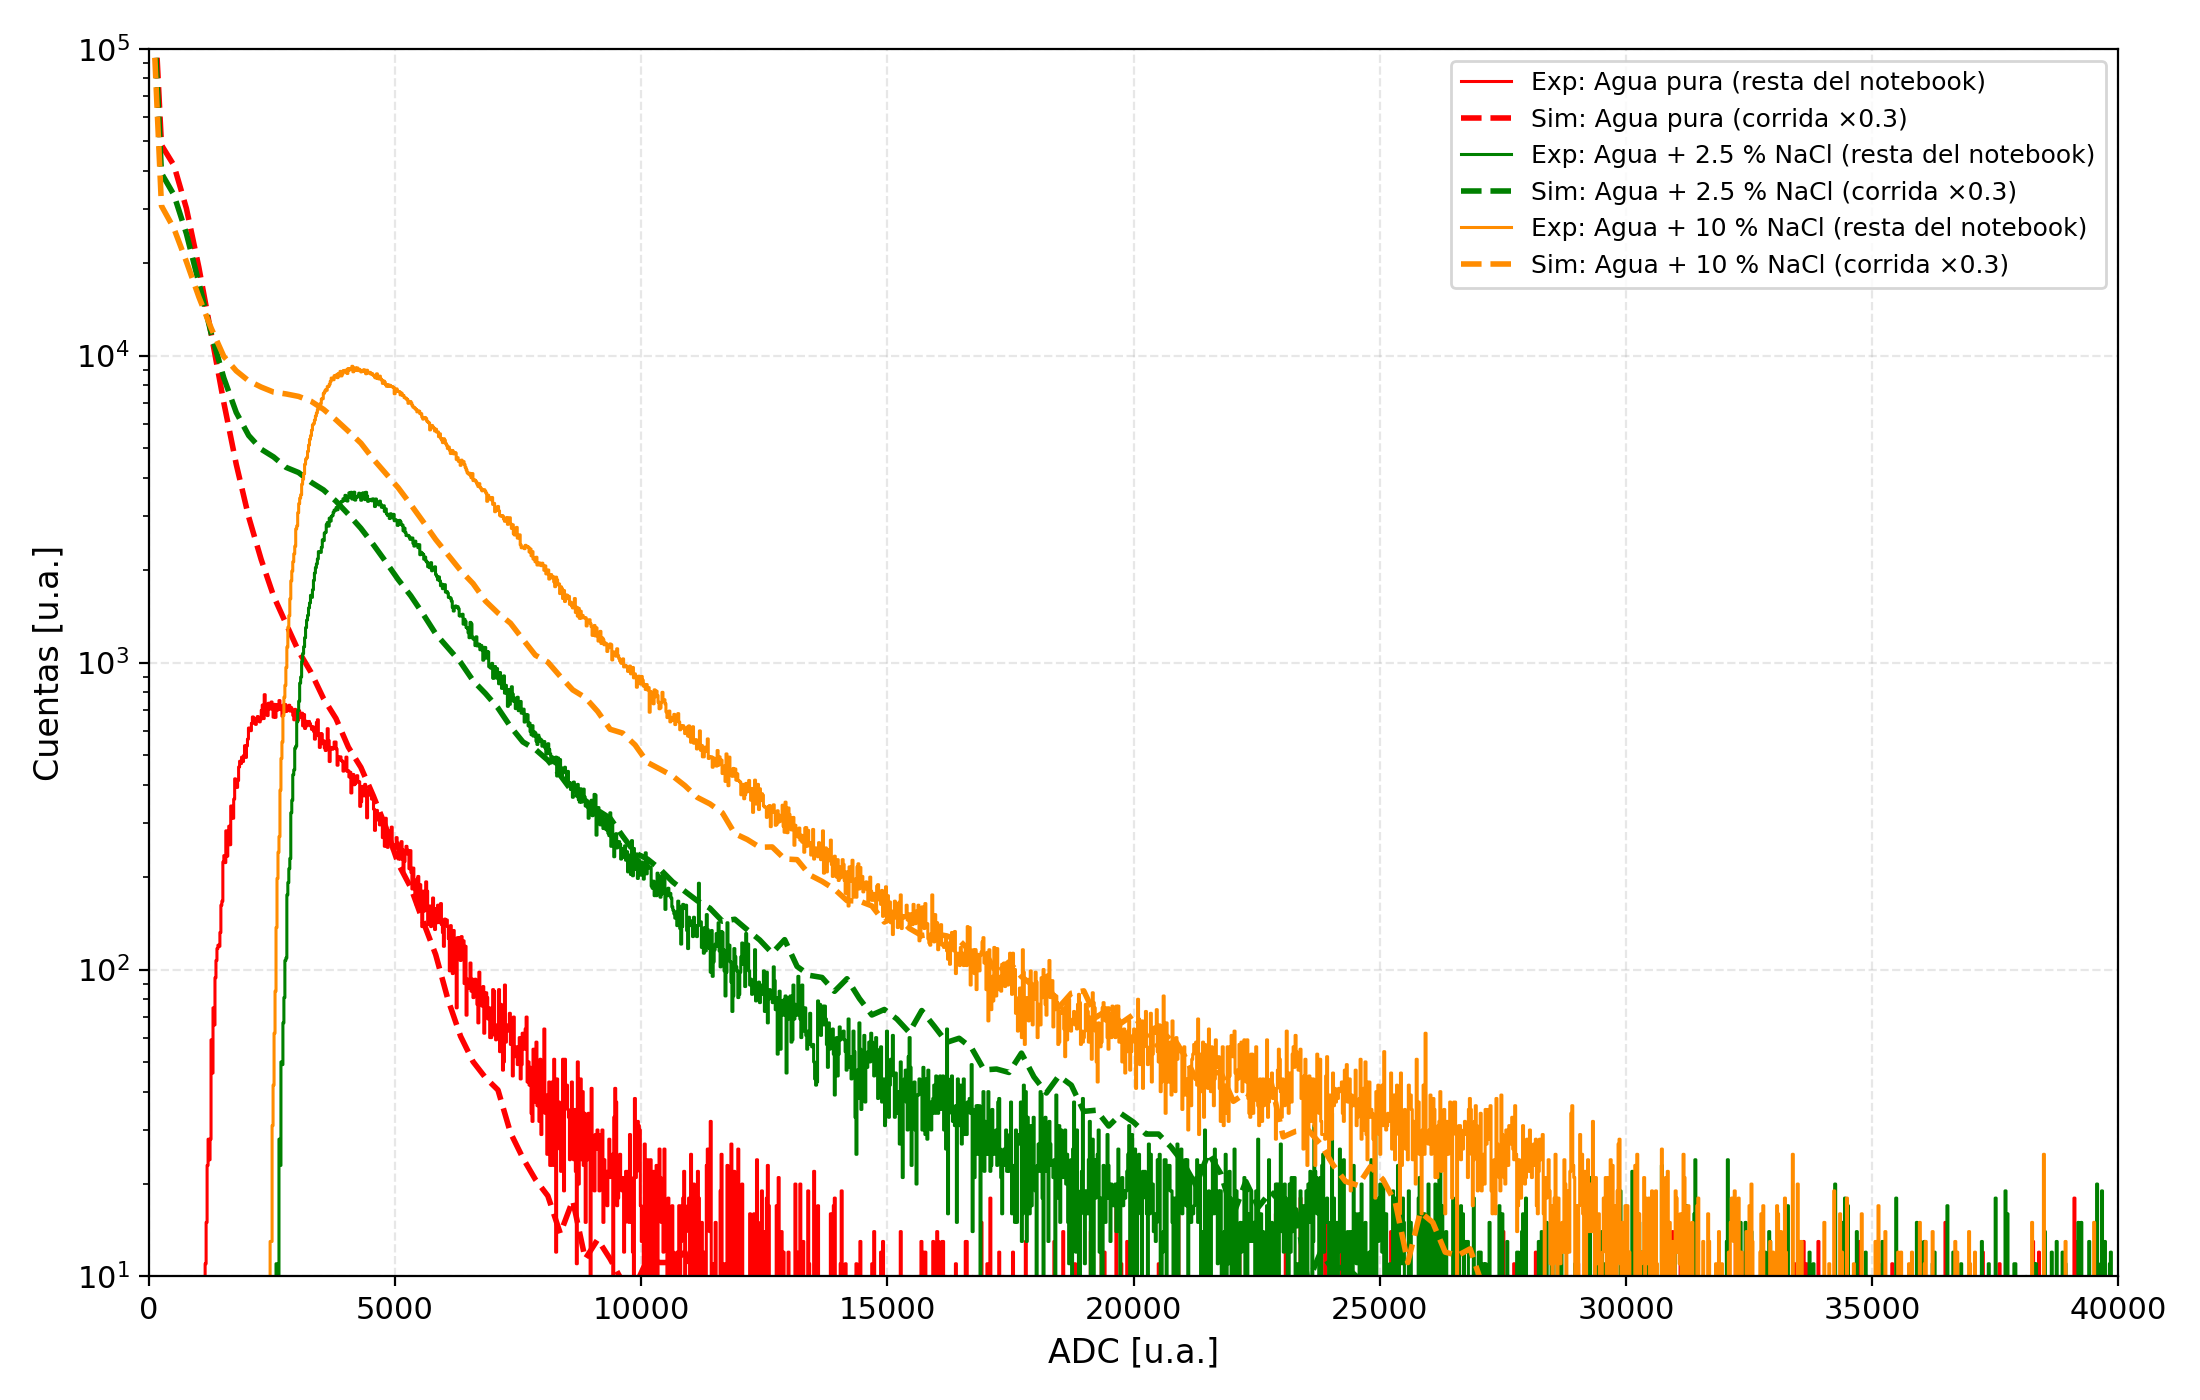

In [14]:
from IPython.display import Image
Image('figuras/fig09_reproduccion_notebook.png', width=820)

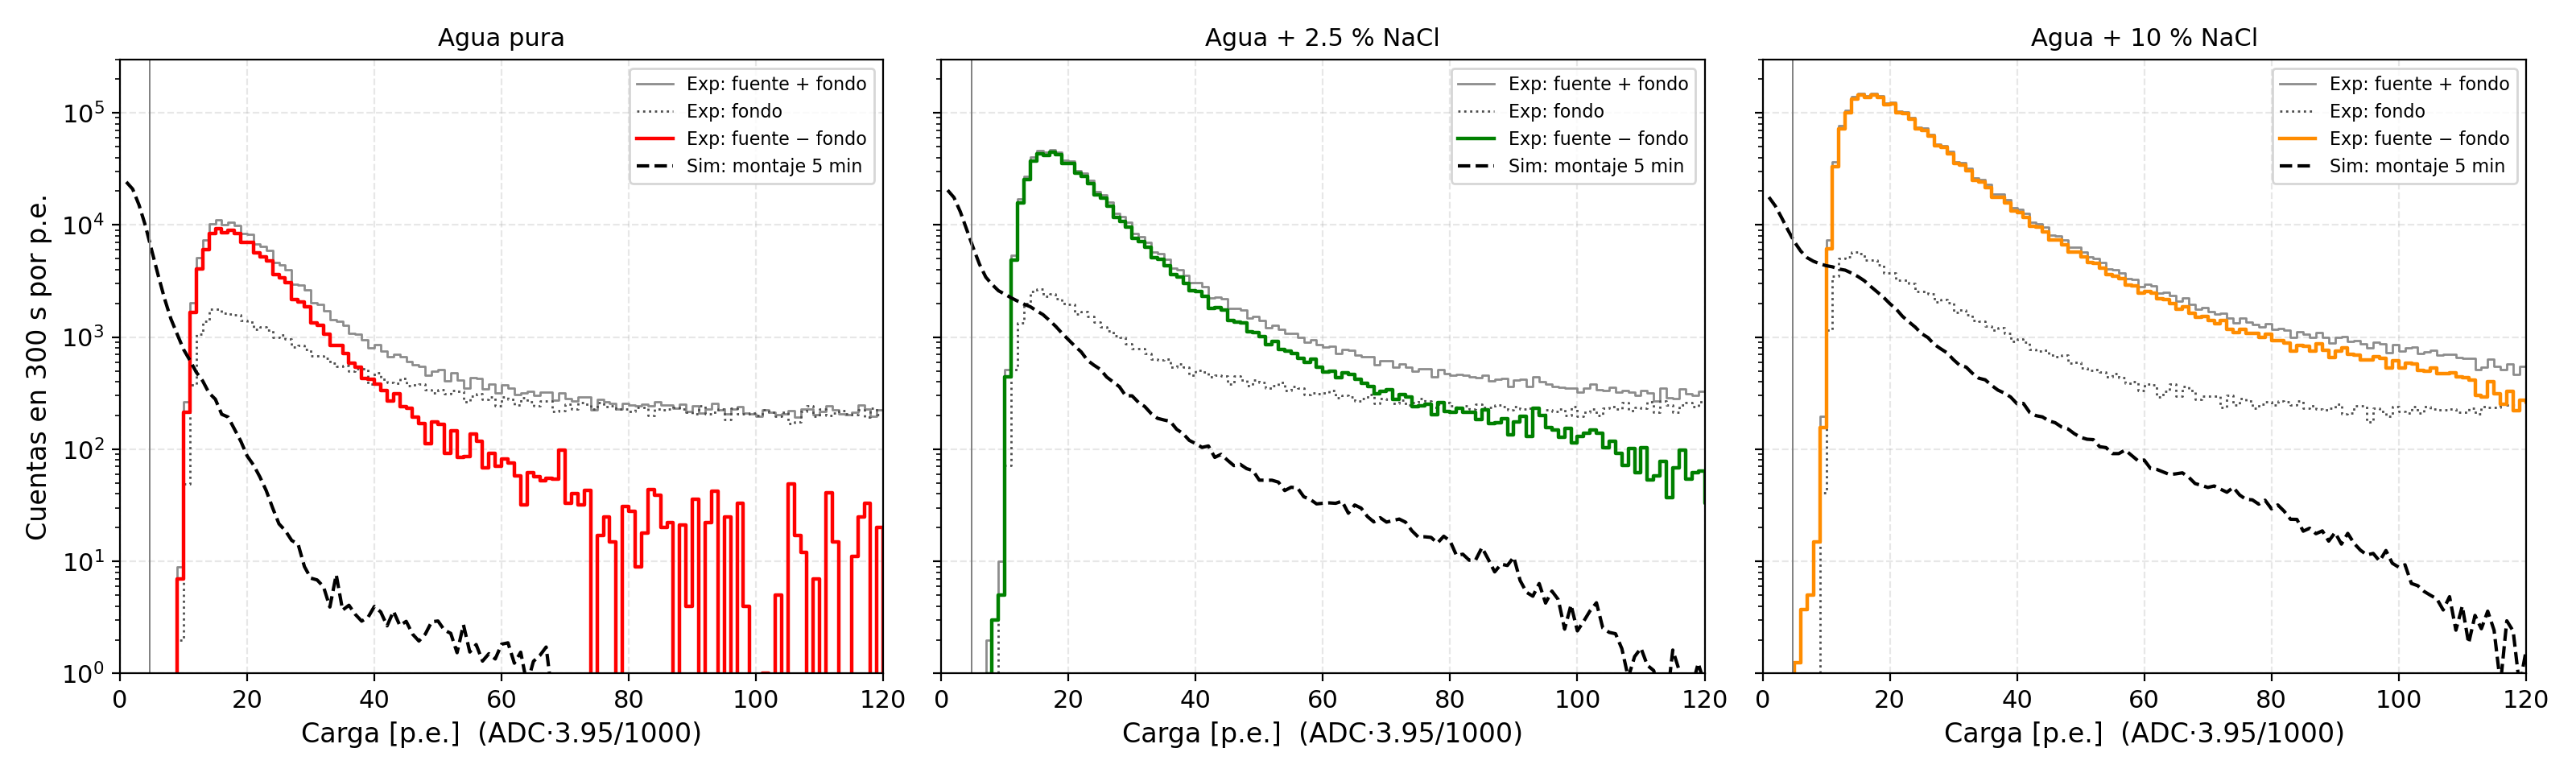

In [15]:
from IPython.display import Image
Image('figuras/fig08_experimento_vs_simulacion.png', width=820)

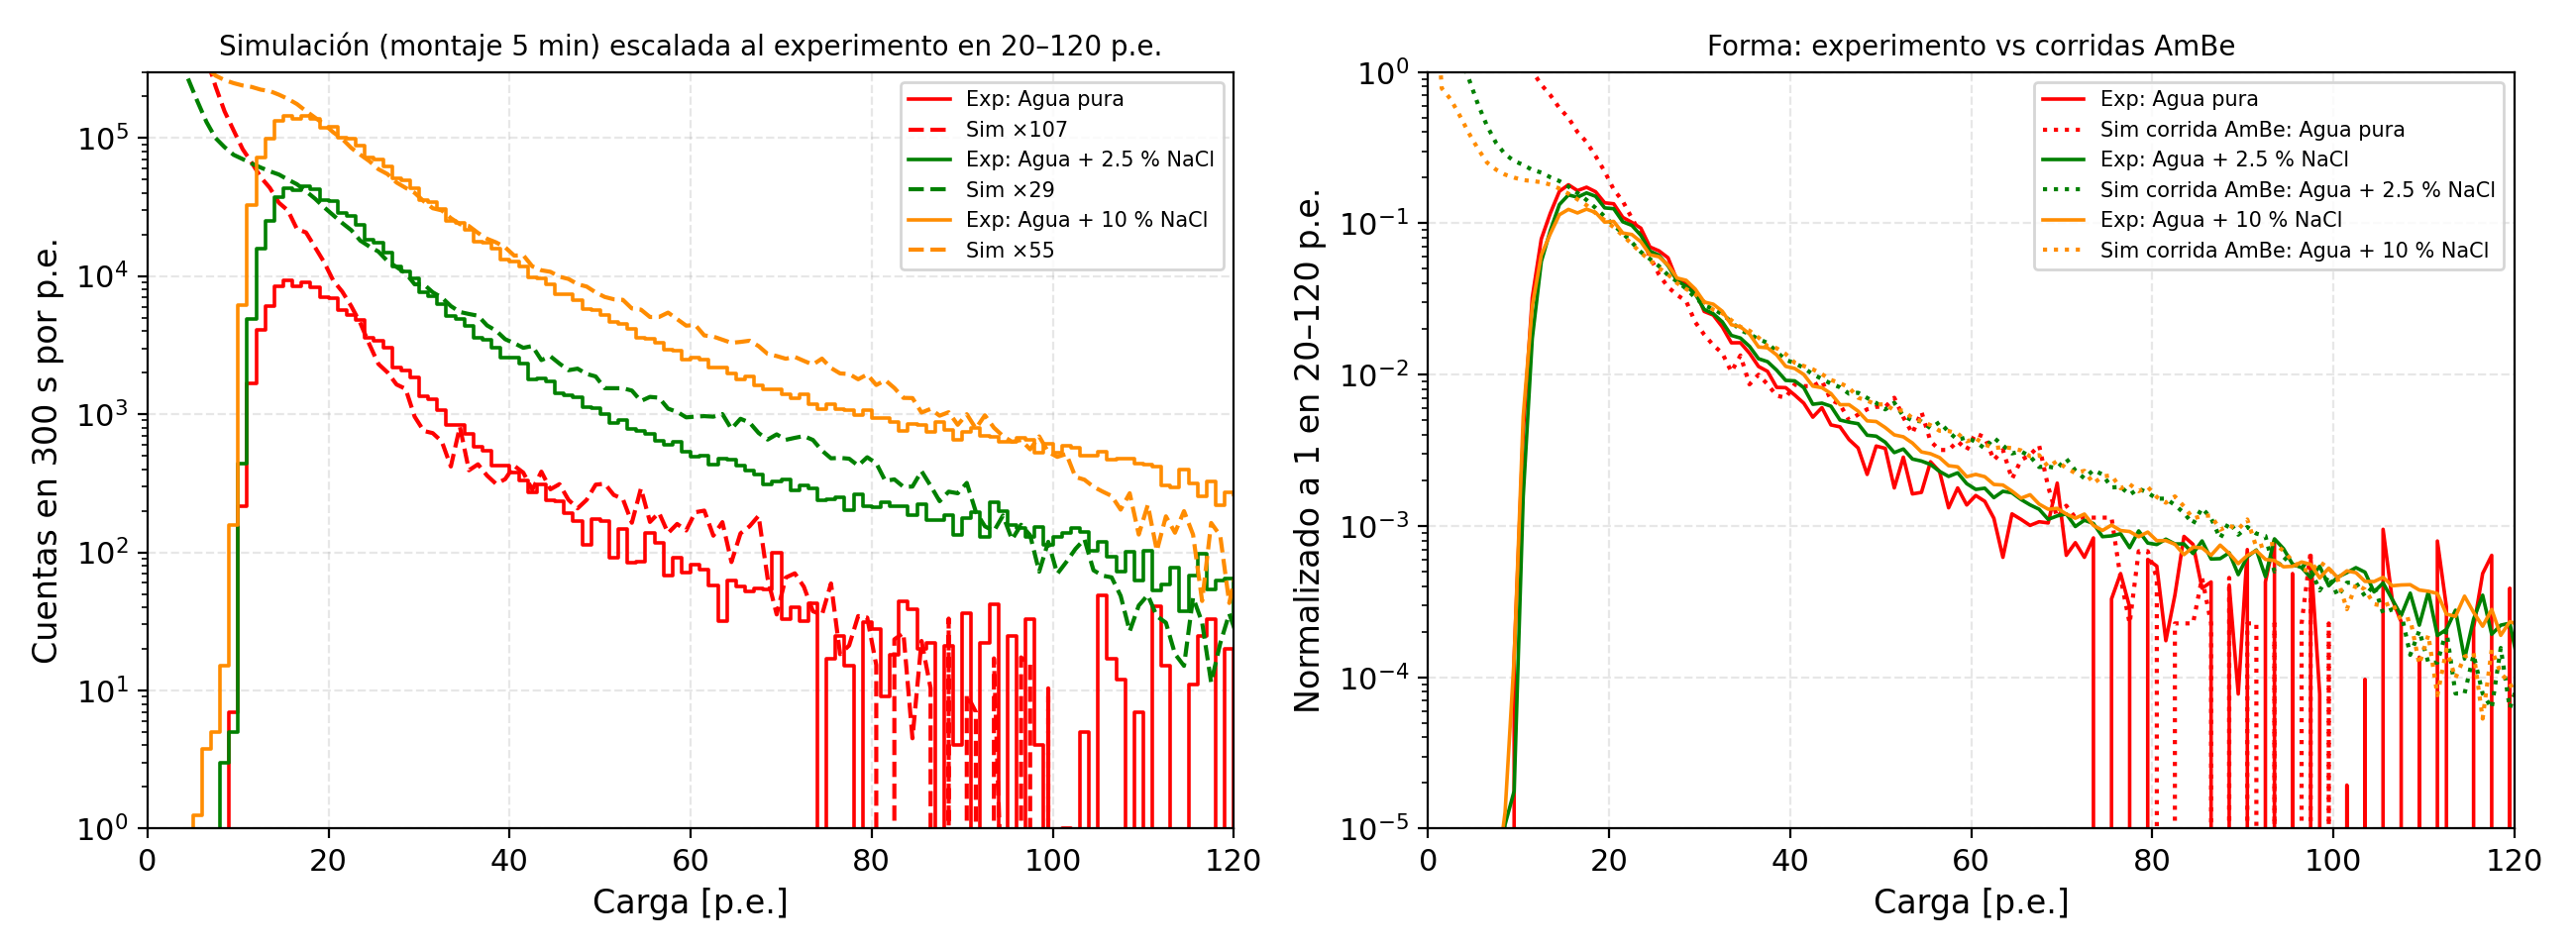

In [16]:
from IPython.display import Image
Image('figuras/fig10_forma_exp_vs_sim.png', width=820)

**Resultados:** (1) el pico de muones del fondo cae en 154–162 p.e. en los tres medios, así que la calibración vale aunque cambien el umbral (800/1000/1080) y la HV; (2) por encima de 10 p.e. el experimento tiene 28 / 21 / 39 veces más cuentas netas que el montaje modelado (373 272 n), lo que equivale a ~8–15 millones de neutrones incidentes en 5 min (1.2–2.2 % de 1 Ci); (3) la forma en NaCl coincide entre 20 y 60 p.e., pero en agua pura el experimento tiene una cola mucho más larga que la simulación (casi igual a la de NaCl): hay una componente de la señal que no depende del medio y que no está simulada (¿gammas de 4.44 MeV de la fuente, neutrones por el costado?); (4) el NaCl aumenta las cuentas con Q ≥ 20 p.e. ×5.4 y ×22 en el experimento, frente a ×20 y ×44 en la simulación.

## 5. Histogramas sin fondo y neutrones por medio
Se reproducen exactamente los `Diferencia-datos-A-*.dat` de `Detector-prototipo/Comparacion-robusta-fondo-neutrones-*` (carga = parte positiva de toda la traza, línea base = mediana de las 20 primeras muestras, todos los disparos). Luego se normalizan por tiempo a 300 s (la toma con fuente de 10 % dura 240 s). Detectados: Q ≥ 12 p.e.; incidentes = detectados / eficiencia simulada; capturados = incidentes × capturas por neutrón.

In [17]:
runpy.run_path('scripts/histogramas_sin_fondo.py', run_name='__main__');
pd.DataFrame(json.load(open('resultados/sin_fondo_resumen.json'))['medios']).T[['detectados_300s','neutrones_incidentes_300s','pct_de_emitidos_1Ci','neutrones_capturados_300s','P_captura_dado_detectado','carga_media_detectados_pe','carga_media_sim_pe']]

pura {"duracion_fuente_s": 300, "duracion_fondo_s": 300, "disparos_fuente": 563961, "disparos_fondo": 125401, "reproduce_archivo_original": true, "max_dif_vs_original": 0, "netos_todos_300s": 438559.99999999994, "netos_sin_normalizar_notebook": 438542, "pico_muones_fondo_pe": 154.05, "umbral_pe": 12, "detectados_300s": 258816.99999999997, "u_detectados": 676.7237250163466, "tasa_detectados_s": 862.7233333333332, "eficiencia_sim_por_neutron": 0.007076698225422748, "neutrones_incidentes_300s": 36573129.410861485, "u_neutrones_incidentes": 95627.04293158134, "pct_de_emitidos_1Ci": 5.491460872501724, "capturas_por_neutron_sim": 0.4149177208936334, "neutrones_capturados_300s": 15174839.50110256, "P_captura_dado_detectado": 0.8963591341102304, "detectados_con_captura_300s": 231992.98201300748, "detectados_sin_captura_300s": 26824.0179869925, "carga_media_detectados_pe": 18.191958565801322, "carga_media_sim_pe": 16.97676936346023}


nacl25 {"duracion_fuente_s": 300, "duracion_fondo_s": 299, "disparos_fuente": 1099688, "disparos_fondo": 114227, "reproduce_archivo_original": true, "max_dif_vs_original": 0, "netos_todos_300s": 985078.9698996656, "netos_sin_normalizar_notebook": 985467, "pico_muones_fondo_pe": 138.25, "umbral_pe": 12, "detectados_300s": 895347.0568561873, "u_detectados": 1054.0745167047571, "tasa_detectados_s": 2984.4901895206244, "eficiencia_sim_por_neutron": 0.060660580756124224, "neutrones_incidentes_300s": 14759948.646976877, "u_neutrones_incidentes": 17376.597842715822, "pct_de_emitidos_1Ci": 2.2162085055520837, "capturas_por_neutron_sim": 0.4599621323055305, "neutrones_capturados_300s": 6789017.452383614, "P_captura_dado_detectado": 0.9886430722964946, "detectados_con_captura_300s": 885178.6650619253, "detectados_sin_captura_300s": 10168.391794262041, "carga_media_detectados_pe": 20.64889994062886, "carga_media_sim_pe": 22.49804748697277}


nacl10 {"duracion_fuente_s": 240, "duracion_fondo_s": 299, "disparos_fuente": 2488416, "disparos_fondo": 185751, "reproduce_archivo_original": true, "max_dif_vs_original": 0, "netos_todos_300s": 2924147.759197324, "netos_sin_normalizar_notebook": 2302775, "pico_muones_fondo_pe": 146.15, "umbral_pe": 12, "detectados_300s": 2763179.5819397992, "u_detectados": 1957.2406470321553, "tasa_detectados_s": 9210.598606465997, "eficiencia_sim_por_neutron": 0.1262495378705073, "neutrones_incidentes_300s": 21886651.060647532, "u_neutrones_incidentes": 15502.952961615389, "pct_de_emitidos_1Ci": 3.2862839430401696, "capturas_por_neutron_sim": 0.5385987665090035, "neutrones_capturados_300s": 11788123.264277734, "P_captura_dado_detectado": 0.9948689892572724, "detectados_con_captura_300s": 2749001.677820781, "detectados_sin_captura_300s": 14177.904119018649, "carga_media_detectados_pe": 23.20698016421144, "carga_media_sim_pe": 22.960242580344246}


,detectados_300s,neutrones_incidentes_300s,pct_de_emitidos_1Ci,neutrones_capturados_300s,P_captura_dado_detectado,carga_media_detectados_pe,carga_media_sim_pe
pura,258817.0,36573129.410861,5.491461,15174839.501103,0.896359,18.191959,16.976769
nacl25,895347.056856,14759948.646977,2.216209,6789017.452384,0.988643,20.6489,22.498047
nacl10,2763179.58194,21886651.060648,3.286284,11788123.264278,0.994869,23.20698,22.960243


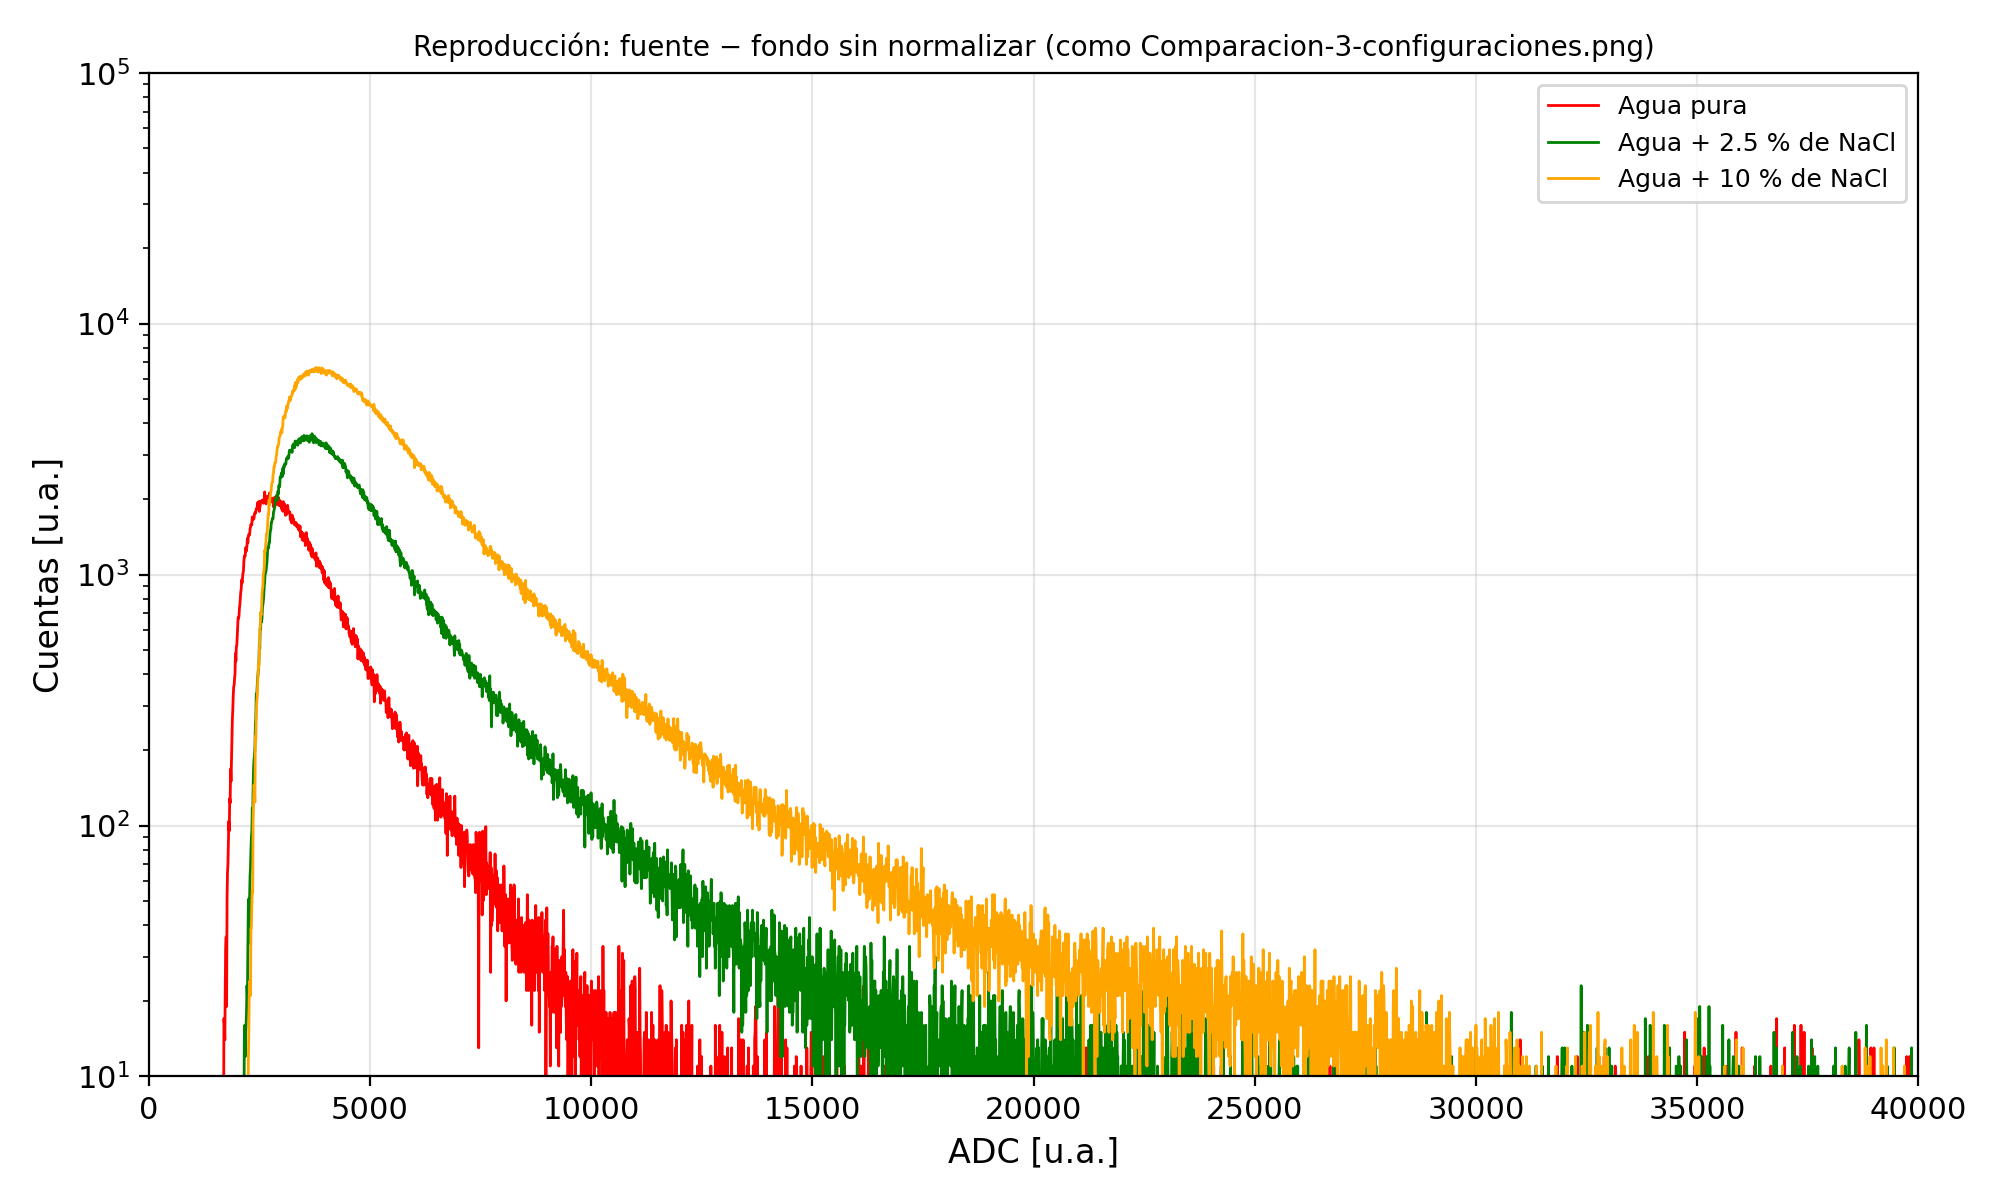

In [18]:
from IPython.display import Image
Image('figuras/fig11_sin_fondo_reproduccion.png', width=820)

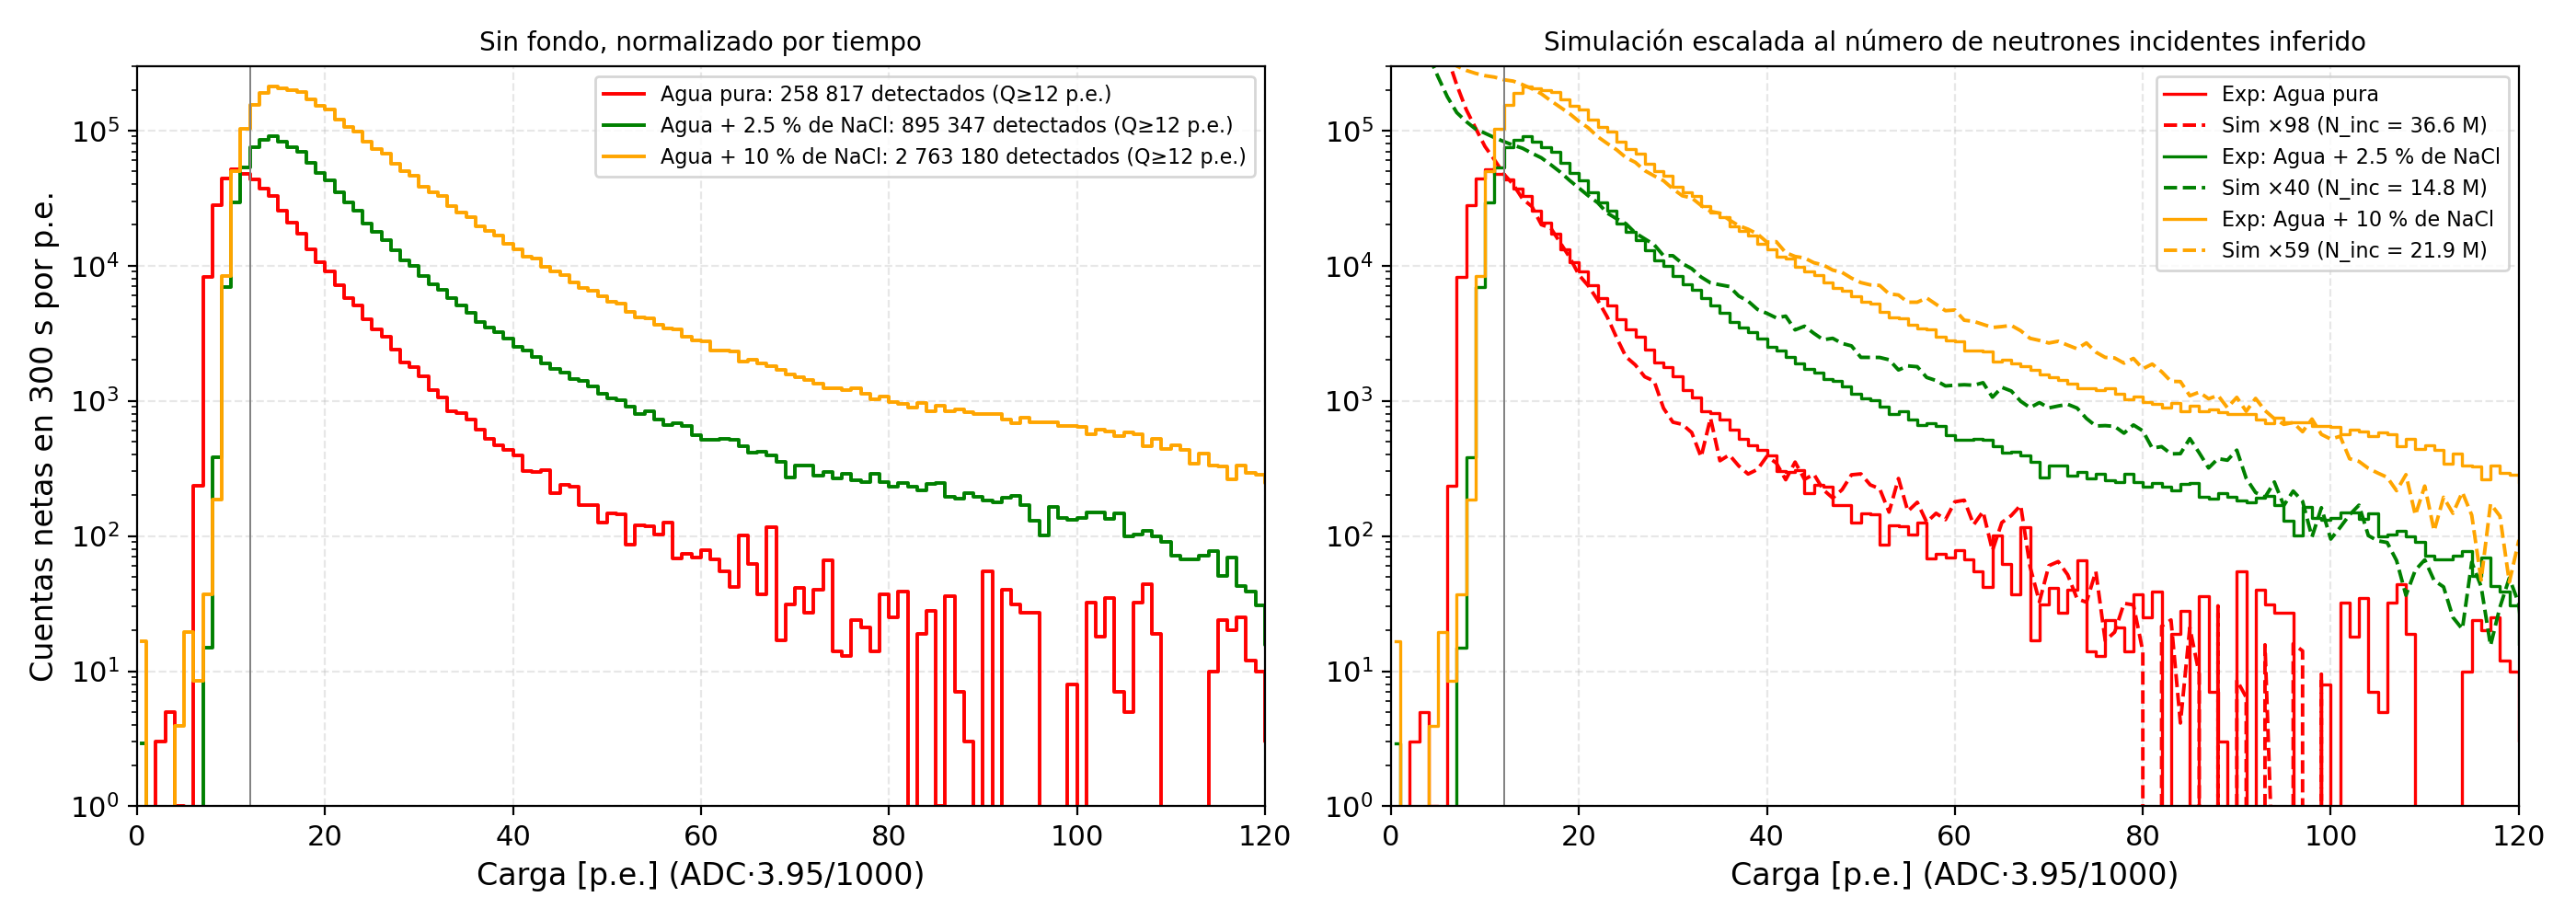

In [19]:
from IPython.display import Image
Image('figuras/fig12_sin_fondo_normalizado.png', width=820)

**Resultado (5 min):** detectados 258 817 / 895 347 / 2 763 180; incidentes 36.6 / 14.8 / 21.9 M (5.5 / 2.2 / 3.3 % de 1 Ci); capturados 15.2 / 6.8 / 11.8 M (agua pura / 2.5 % / 10 %). La forma coincide con la simulación en los tres medios; el número de incidentes debería ser igual en los tres y no lo es (×2.5).

In [20]:
runpy.run_path('scripts/escribir_informe.py', run_name='__main__')

ok


{'__name__': '__main__',
 '__doc__': 'Escribe informe/Informe-corridas-AmBe.tex a partir de resultados/resumen_corridas.json.',
 '__package__': '',
 '__loader__': None,
 '__spec__': None,
 '__file__': 'scripts/escribir_informe.py',
 '__cached__': None,
 '__builtins__': {'__name__': 'builtins',
  '__doc__': "Built-in functions, types, exceptions, and other objects.\n\nThis module provides direct access to all 'built-in'\nidentifiers of Python; for example, builtins.len is\nthe full name for the built-in function len().\n\nThis module is not normally accessed explicitly by most\napplications, but can be useful in modules that provide\nobjects with the same name as a built-in value, but in\nwhich the built-in of that name is also needed.",
  '__package__': '',
  '__loader__': _frozen_importlib.BuiltinImporter,
  '__spec__': ModuleSpec(name='builtins', loader=<class '_frozen_importlib.BuiltinImporter'>, origin='built-in'),
  '__build_class__': <function __build_class__>,
  '__import__': <f